# Classificação do hype de GTA VI

Classificação multiclasse das respostas de um questionário sobre expectativas para GTA VI, comparando regressão logística treinada por gradiente descendente (LR-GD) e uma árvore de decisão (AD) implementada do zero.

## 1. Definição da tarefa

- **Alvo:** `hype_score_1to10` reagrupado em **5 classes ordenadas** (seção 2), para equilibrar as classes.
- **Removidos de X:**
  - `respondent_id`: apenas o identificador da linha (`R100000`, `R100001`, …), sem informação sobre o respondente;
  - `overall_sentiment`: é uma função exata da nota (1–4 → Neutral/Cautious, 5–7 → Positive, 8–10 → Very Positive), ou seja, uma versão resumida do próprio alvo. Mantê-lo seria vazamento de dados (comprovado na seção 2);
  - `hype_score_1to10`: nota original, da qual o alvo é derivado.
- **Texto:** `most_anticipated_feature` recebe TF-IDF. É o único campo textual da base, com 10 frases possíveis; os demais atributos são estruturados.

## Roteiro

Estudo introdutório → reagrupamento do alvo e verificação de vazamento → divisão estratificada 60/20/20 → TF-IDF + atributos estruturados → AD própria → LR-GD com quatro penalidades e busca de alpha → consistência 30/60/90% → cinco curvas → seleção pela validação → teste de todos os casos → três matrizes de confusão.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import time
import numpy as np
import pandas as pd
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
import sklearn
import scipy
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.linear_model import SGDClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

# Funciona com execução iniciada na raiz ou na pasta notebooks.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'datasets/gta6_fan_expectations_2026.csv').is_file())
DATASET = ROOT / 'datasets/gta6_fan_expectations_2026.csv'
OUT = ROOT / 'docs/gta6_classificacao/resultados'
FIG = OUT / 'figuras'
FIG.mkdir(parents=True, exist_ok=True)
NOTA = 'hype_score_1to10'
TARGET = 'classe_hype'
SEED = 42
SEEDS = [42, 43, 44]
FRACTIONS = [0.10, 0.30, 0.60, 0.90, 1.00]
MAX_DEPTH = 12
EPOCHS = 160
ALPHAS = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'scikit_learn': sklearn.__version__,
            'scipy': scipy.__version__}
print(VERSIONS)
plt.rcParams.update({'figure.figsize': (9, 5), 'axes.grid': True})

raw = pd.read_csv(DATASET)
# respondent_id é só o identificador da linha: conferimos que é único e o removemos.
assert raw.respondent_id.is_unique
df = raw.drop(columns='respondent_id').reset_index(drop=True)
assert len(df) >= 2000 and not df[NOTA].isna().any()
print('Dimensões (sem ID):', df.shape)
display(df.head())

{'python': '3.13.16', 'numpy': '2.5.3', 'pandas': '3.0.5', 'scikit_learn': '1.9.1', 'scipy': '1.18.1'}
Dimensões (sem ID): (6000, 19)


,age,gender,region,primary_platform,favorite_previous_gta,years_following_gta6,primary_info_source,trailer1_times_watched,most_anticipated_feature,hype_score_1to10,confidence_rockstar_delivers_1to5,preorder_intent,willingness_to_pay_usd,expected_firstweek_hours,expects_release_delay,worried_about_price,follows_rockstar_socials,hype_change_vs_6mo_ago,overall_sentiment
0,30,Male,Europe,Undecided,GTA San Andreas,5,Reddit,13,Better driving physics,10,5,No,96.0,19,Yes,No,Yes,Same,Very Positive
1,29,Male,Europe,PC,GTA San Andreas,4,X/Twitter,15,Dual protagonists (Jason & Lucia),10,3,Yes,70.0,10,No,No,No,Same,Very Positive
2,28,Female,Europe,Xbox Series X/S,GTA V,6,YouTube,9,Story & narrative depth,7,5,Maybe,81.0,6,No,No,Yes,Increased,Positive
3,30,Male,Europe,Xbox Series X/S,GTA Vice City,8,Gaming news sites,6,Online/multiplayer mode,8,4,Yes,80.0,11,Yes,No,Yes,Increased,Very Positive
4,40,Male,Europe,PlayStation 5,GTA V,10,TikTok,8,Realistic economy & businesses,8,4,No,69.0,25,Yes,Yes,No,Same,Very Positive


## 2. Estudo introdutório

Tipos, cardinalidade, ausências, duplicações, estatísticas numéricas e distribuição das notas. Os textos repetidos de `most_anticipated_feature` são opções do questionário, não linhas duplicadas.

In [2]:
schema = pd.DataFrame({'tipo': df.dtypes.astype(str), 'valores_unicos': df.nunique(),
                       'ausentes': df.isna().sum(), 'ausentes_pct': df.isna().mean() * 100})
display(schema)
display(df.describe().T)
print('Linhas duplicadas:', int(df.duplicated().sum()))
display(df.most_anticipated_feature.value_counts().rename('quantidade').to_frame())
schema.to_csv(OUT / 'auditoria_colunas.csv')

,tipo,valores_unicos,ausentes,ausentes_pct
age,int64,43,0,0.0
gender,str,4,60,1.0
region,str,6,0,0.0
primary_platform,str,5,0,0.0
favorite_previous_gta,str,7,0,0.0
years_following_gta6,int64,14,0,0.0
primary_info_source,str,8,0,0.0
trailer1_times_watched,int64,21,0,0.0
most_anticipated_feature,str,10,0,0.0
hype_score_1to10,int64,10,0,0.0


,count,mean,std,min,25%,50%,75%,max
age,6000.0,26.120500,7.665210,13.0,20.0,26.0,31.0,59.0
years_following_gta6,6000.0,6.030833,2.911751,0.0,4.0,6.0,8.0,13.0
trailer1_times_watched,6000.0,8.785333,3.032675,0.0,7.0,9.0,11.0,20.0
hype_score_1to10,6000.0,7.777500,1.797832,1.0,7.0,8.0,9.0,10.0
confidence_rockstar_delivers_1to5,6000.0,3.700667,0.970854,1.0,3.0,4.0,4.0,5.0
willingness_to_pay_usd,5880.0,71.691497,16.133165,6.0,61.0,72.0,83.0,120.0
expected_firstweek_hours,6000.0,16.451000,11.491937,0.0,8.0,14.0,22.0,101.0


Linhas duplicadas: 0


,quantidade
most_anticipated_feature,
Open-world Vice City map,954
Dual protagonists (Jason & Lucia),905
Story & narrative depth,718
Online/multiplayer mode,643
Realistic economy & businesses,548
Map size & exploration,527
Improved police/AI systems,466
Deeper character customization,434
Graphics & ray tracing,424


### 2.1 Vazamento: `overall_sentiment` é derivado da nota

A tabela cruzada mostra que cada faixa de nota corresponde a exatamente um sentimento, sem exceção. O atributo funciona como uma versão resumida do alvo e por isso sai de X. Os demais atributos têm relação apenas estatística com a nota: por exemplo, quem não jogou GTA tende a dar notas baixas, mas aparece em todas as faixas.

In [3]:
leak = pd.crosstab(df[NOTA], df.overall_sentiment)
display(leak)
# Cada nota tem um único sentimento -> o sentimento é determinado pela nota.
assert (leak.gt(0).sum(axis=1) == 1).all()
# Nenhum outro atributo categórico tem essa propriedade.
for column in df.select_dtypes(exclude='number').columns.drop('overall_sentiment'):
    assert not (pd.crosstab(df[NOTA], df[column]).gt(0).sum(axis=1) == 1).all(), column
leak.to_csv(OUT / 'vazamento_overall_sentiment.csv')

overall_sentiment,Neutral/Cautious,Positive,Very Positive
hype_score_1to10,,,
1,2,0,0
2,19,0,0
3,69,0,0
4,192,0,0
5,0,419,0
6,0,746,0
7,0,1025,0
8,0,0,1172
9,0,0,1032


### 2.2 Reagrupamento do alvo em 5 classes

As notas originais são muito desbalanceadas: a nota 1 tem 2 registros e a nota 2 tem 19, o que impede uma estratificação 60/20/20. Agrupamos as notas baixas até a nota 6, que é a primeira faixa com volume comparável ao das notas altas, e mantemos as notas 7 a 10 separadas. As faixas foram definidas pela distribuição do alvo, antes de qualquer treino.

|Classe|Notas|
|---|---|
|Baixo|1–6|
|Alto|7|
|Muito alto|8|
|Altíssimo|9|
|Máximo|10|

A maior classe fica com cerca de 1,4× o tamanho da menor; com as 10 notas originais essa razão era de 662×.

,quantidade,pct
classe_hype,,
Baixo,1447,24.1
Alto,1025,17.1
Muito alto,1172,19.5
Altíssimo,1032,17.2
Máximo,1324,22.1


Razão maior/menor classe — original: 662x; agrupado: 1.41x


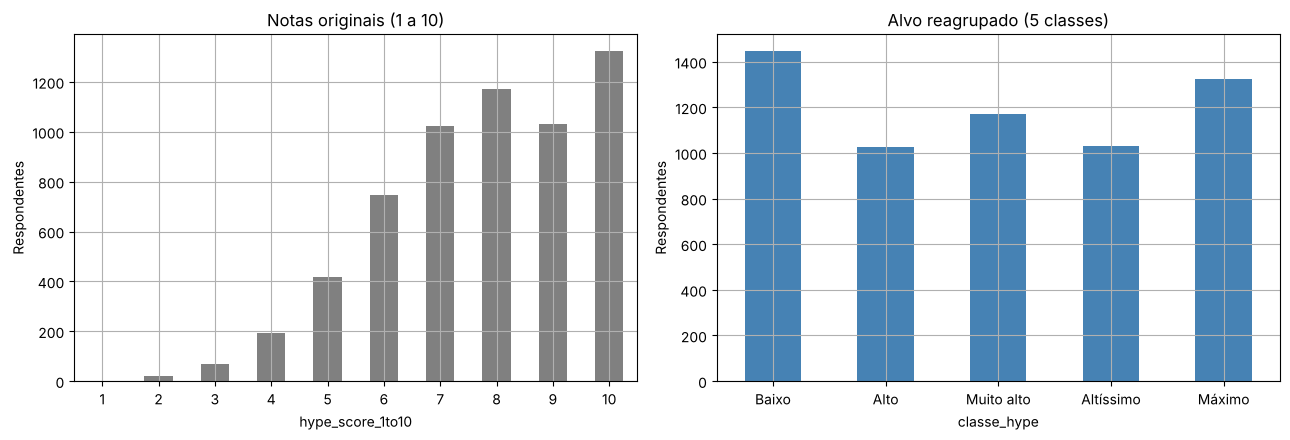

In [4]:
FAIXAS = {'Baixo': range(1, 7), 'Alto': [7], 'Muito alto': [8], 'Altíssimo': [9], 'Máximo': [10]}
CLASSES = np.array(list(FAIXAS))
mapa = {nota: classe for classe, notas in FAIXAS.items() for nota in notas}
df[TARGET] = df[NOTA].map(mapa)
assert not df[TARGET].isna().any() and df[TARGET].nunique() == 5

original = df[NOTA].value_counts().sort_index()
agrupado = df[TARGET].value_counts().reindex(CLASSES)
display(agrupado.rename('quantidade').to_frame().assign(pct=lambda t: (t.quantidade / len(df) * 100).round(1)))
print('Razão maior/menor classe — original: %.0fx; agrupado: %.2fx'
      % (original.max() / original.min(), agrupado.max() / agrupado.min()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
original.plot.bar(ax=axes[0], color='gray')
axes[0].set(title='Notas originais (1 a 10)', xlabel='hype_score_1to10', ylabel='Respondentes')
agrupado.plot.bar(ax=axes[1], color='steelblue')
axes[1].set(title='Alvo reagrupado (5 classes)', xlabel='classe_hype', ylabel='Respondentes')
for ax in axes:
    ax.tick_params(axis='x', rotation=0)
fig.tight_layout()
fig.savefig(FIG / 'eda_classes.png', dpi=150)
plt.show()
agrupado.rename('quantidade').to_csv(OUT / 'distribuicao_classes.csv')

## 3. Partições

20% para teste; dos 80% restantes, 25% para validação (20% do total), sobrando 60% para treino. Divisão estratificada pelo alvo, semente 42. O teste fica intocado até a seleção dos modelos.

Os tamanhos 30%, 60% e 90% referem-se aos 60% de treino (18%, 36% e 54% do total). Para cada semente os subconjuntos são estratificados e aninhados (30% ⊂ 60% ⊂ 90%).

In [5]:
train_val, test = train_test_split(df, test_size=0.20, stratify=df[TARGET], random_state=SEED)
train, val = train_test_split(train_val, test_size=0.25, stratify=train_val[TARGET], random_state=SEED)
assert (len(train), len(val), len(test)) == (3600, 1200, 1200)
sets = [set(frame.index) for frame in [train, val, test]]
assert not sets[0] & sets[1] and not sets[0] & sets[2] and not sets[1] & sets[2]
assert set.union(*sets) == set(df.index)
split_table = pd.DataFrame({name: frame[TARGET].value_counts().reindex(CLASSES, fill_value=0)
                           for name, frame in [('treino', train), ('validacao', val), ('teste', test)]})
display(split_table)
split_table.to_csv(OUT / 'particoes_por_classe.csv')
pd.concat([pd.DataFrame({'linha': frame.index, 'particao': name})
           for name, frame in [('treino', train), ('validacao', val), ('teste', test)]]
          ).to_csv(OUT / 'particoes_ids.csv', index=False)

REMOVIDOS = [TARGET, NOTA, 'overall_sentiment']
FEATURES = [c for c in df if c not in REMOVIDOS]
assert not set(REMOVIDOS) & set(FEATURES)
X_train, y_train = train[FEATURES], train[TARGET].to_numpy()
X_val, y_val = val[FEATURES], val[TARGET].to_numpy()
print('Atributos usados:', FEATURES)


def subconjuntos_aninhados(frame, seed):
    pools = {1.0: frame}
    current = frame
    for fraction in sorted([f for f in FRACTIONS if f < 1], reverse=True):
        size = int(round(len(frame) * fraction))
        current, _ = train_test_split(current, train_size=size, stratify=current[TARGET],
                                      random_state=seed)
        pools[fraction] = current
    for small, large in zip(FRACTIONS[:-1], FRACTIONS[1:]):
        assert set(pools[small].index) <= set(pools[large].index)
    for fraction, sample in pools.items():
        assert len(sample) == round(len(frame) * fraction)
        assert set(sample[TARGET]) == set(CLASSES)
    return pools

POOLS = {seed: subconjuntos_aninhados(train, seed) for seed in SEEDS}
size_table = pd.DataFrame([{'fracao_treino': f, 'n_treino': len(POOLS[42][f]),
                           'fracao_total': len(POOLS[42][f]) / len(df)} for f in FRACTIONS])
display(size_table)
size_table.to_csv(OUT / 'tamanhos_treino.csv', index=False)
pd.concat([pd.DataFrame({'linha': sample.index, 'semente': seed, 'fracao_treino': fraction})
           for seed, pools in POOLS.items() for fraction, sample in pools.items()]
         ).to_csv(OUT / 'subconjuntos_ids.csv', index=False)

,treino,validacao,teste
classe_hype,,,
Baixo,868,290,289
Alto,615,205,205
Muito alto,704,234,234
Altíssimo,619,206,207
Máximo,794,265,265


Atributos usados: ['age', 'gender', 'region', 'primary_platform', 'favorite_previous_gta', 'years_following_gta6', 'primary_info_source', 'trailer1_times_watched', 'most_anticipated_feature', 'confidence_rockstar_delivers_1to5', 'preorder_intent', 'willingness_to_pay_usd', 'expected_firstweek_hours', 'expects_release_delay', 'worried_about_price', 'follows_rockstar_socials', 'hype_change_vs_6mo_ago']


,fracao_treino,n_treino,fracao_total
0,0.1,360,0.06
1,0.3,1080,0.18
2,0.6,2160,0.36
3,0.9,3240,0.54
4,1.0,3600,0.60


## 4. Representação TF-IDF + dados estruturados

TF sublinear = 1 + log(contagem); IDF suavizado = log((1+n)/(1+df(t))) + 1; vetor normalizado pela norma L2. Unigramas e bigramas de `most_anticipated_feature`.

Numéricos: imputação pela mediana e padronização. Categóricos: categoria "Ausente" e one-hot. **Cada subconjunto de treino ajusta seu próprio pré-processador** (vocabulário, IDF, medianas, médias, desvios e categorias); validação e teste só passam por `transform`. A mesma representação vai para a LR e para a AD.

In [6]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def criar_preprocessador(frame):
    """Ajustar SOMENTE no subconjunto de treino de cada experimento."""
    numeric = frame.select_dtypes(include='number').columns.tolist()
    categorical = [c for c in frame.columns if c not in numeric and c != 'most_anticipated_feature']
    transformers = [('texto', TfidfVectorizer(ngram_range=(1, 2), lowercase=True,
                     sublinear_tf=True, smooth_idf=True, norm='l2', min_df=1),
                     'most_anticipated_feature')]
    if numeric:
        transformers.append(('numericos', Pipeline([
            ('imputar', SimpleImputer(strategy='median')),
            ('escala', StandardScaler())]), numeric))
    if categorical:
        transformers.append(('categoricos', Pipeline([
            ('imputar', SimpleImputer(strategy='constant', fill_value='Ausente')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical))
    return ColumnTransformer(transformers, sparse_threshold=1.0)


In [7]:
processor_demo = criar_preprocessador(X_train)
Z_demo = processor_demo.fit_transform(X_train)
vocab = processor_demo.named_transformers_['texto']
display(pd.DataFrame({'termo': vocab.get_feature_names_out(), 'idf': vocab.idf_}).head(20))
print('Atributos combinados:', Z_demo.shape[1], 'Vocabulário TF-IDF:', len(vocab.vocabulary_))
print('Exemplos de frases originais:', X_train.most_anticipated_feature.head(3).tolist())

,termo,idf
0,ai,3.508794
1,ai systems,3.508794
2,better,3.733646
3,better driving,3.733646
4,businesses,3.399007
5,character,3.655577
6,character customization,3.655577
7,city,2.845086
8,city map,2.845086
9,customization,3.655577


Atributos combinados: 106 Vocabulário TF-IDF: 57
Exemplos de frases originais: ['Open-world Vice City map', 'Graphics & ray tracing', 'Realistic economy & businesses']


## 5. Árvore de decisão implementada do zero

CART binária multiclasse com Gini = 1 − Σ p(k)². Em cada nó, para cada atributo, ordena os valores, avalia todos os cortes entre valores distintos usando contagens cumulativas e escolhe o de maior redução de impureza. Treino (`fit`) e predição (`predict_proba`, `predict`) são próprios; `sklearn.tree` não é usado.

Critérios de parada: profundidade máxima, nó puro, mínimo de amostras por folha (8) e ganho mínimo. A folha guarda a proporção de cada classe e a predição é a classe de maior proporção. A raiz tem profundidade 0.

In [8]:
import numpy as np
from scipy import sparse


class ArvoreDecisaoPropria:
    """CART multiclasse: busca exata de cortes, Gini e predição próprias.

    Raiz na profundidade zero. Empates: menor índice de atributo/corte/classe.
    Não utiliza sklearn.tree. Conversão densa é limitada a esta base pequena.
    """

    def __init__(self, max_depth=12, min_samples_leaf=8, min_samples_split=2,
                 min_impurity_decrease=1e-10):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.min_samples_split = min_samples_split
        self.min_impurity_decrease = min_impurity_decrease

    @staticmethod
    def _matrix(X):
        X = X.toarray() if sparse.issparse(X) else np.asarray(X, dtype=float)
        if X.ndim != 2 or not np.isfinite(X).all():
            raise ValueError('X deve ser matriz 2D finita, previamente imputada')
        return X

    def fit(self, X, y):
        X = self._matrix(X)
        y = np.asarray(y)
        if y.ndim != 1 or len(y) != len(X) or len(y) == 0:
            raise ValueError('y deve ser vetor não vazio alinhado a X')
        if self.max_depth < 0 or self.min_samples_leaf < 1 or self.min_samples_split < 2:
            raise ValueError('Parâmetros de profundidade/amostras inválidos')
        self.classes_, encoded = np.unique(y, return_inverse=True)
        self.n_features_in_ = X.shape[1]
        self.n_classes_ = len(self.classes_)
        self.node_count_ = 0
        self.depth_ = 0
        self.feature_importances_ = np.zeros(self.n_features_in_)
        self.root_ = self._grow(X, encoded, 0, len(y))
        total = self.feature_importances_.sum()
        if total > 0:
            self.feature_importances_ /= total
        return self

    def _grow(self, X, y, depth, n_total):
        self.node_count_ += 1
        self.depth_ = max(self.depth_, depth)
        n = len(y)
        counts = np.bincount(y, minlength=self.n_classes_)
        impurity = 1.0 - np.sum((counts / n) ** 2)
        node = {'proba': counts / n, 'depth': depth, 'samples': n,
                'gini': impurity, 'feature': None}
        if (depth >= self.max_depth or impurity <= 1e-15
                or n < max(self.min_samples_split, 2 * self.min_samples_leaf)):
            return node
        best_gain = self.min_impurity_decrease
        best = None
        # Todas as fronteiras entre valores distintos são avaliadas.
        for feature in range(X.shape[1]):
            order = np.argsort(X[:, feature], kind='stable')
            values = X[order, feature]
            positions = np.flatnonzero(values[:-1] < values[1:]) + 1
            positions = positions[(positions >= self.min_samples_leaf)
                                  & (n - positions >= self.min_samples_leaf)]
            if not len(positions):
                continue
            cumulative = np.cumsum(np.eye(self.n_classes_)[y[order]], axis=0)
            left = cumulative[positions - 1]
            right = counts - left
            # Gini ponderado = 1 - (sum(L_k²)/nL + sum(R_k²)/nR)/n.
            weighted = 1 - (np.sum(left ** 2, axis=1) / positions
                            + np.sum(right ** 2, axis=1) / (n - positions)) / n
            gains = impurity - weighted
            i = int(np.argmax(gains))
            if gains[i] > best_gain + 1e-14:
                pos = int(positions[i])
                a, b = float(values[pos - 1]), float(values[pos])
                # Evita overflow com sinais opostos e arredondamento para b.
                threshold = a / 2 + b / 2 if a < 0 < b else a + (b - a) / 2
                if not a <= threshold < b:
                    threshold = a
                best_gain = float(gains[i])
                best = feature, float(threshold)
        if best is None:
            return node
        feature, threshold = best
        mask = X[:, feature] <= threshold
        self.feature_importances_[feature] += n / n_total * best_gain
        node.update(feature=feature, threshold=threshold,
                    left=self._grow(X[mask], y[mask], depth + 1, n_total),
                    right=self._grow(X[~mask], y[~mask], depth + 1, n_total))
        return node

    def predict_proba(self, X):
        if not hasattr(self, 'root_'):
            raise ValueError('Treine a árvore antes da predição')
        X = self._matrix(X)
        if X.shape[1] != self.n_features_in_:
            raise ValueError('Quantidade de atributos diferente do treino')
        probabilities = np.empty((len(X), self.n_classes_))
        for i, row in enumerate(X):
            node = self.root_
            while node['feature'] is not None:
                node = node['left'] if row[node['feature']] <= node['threshold'] else node['right']
            probabilities[i] = node['proba']
        return probabilities

    def predict(self, X):
        probabilities = self.predict_proba(X)
        return self.classes_[np.argmax(probabilities, axis=1)]


## 6. Regressão logística por gradiente descendente

`SGDClassifier(loss="log_loss")`: regressão logística otimizada por gradiente descendente estocástico, multiclasse um-contra-resto. Quatro variantes: sem penalidade, Ridge (L2), Lasso (L1) e Elastic Net (50% L1 / 50% L2). Objetivo: média da log-loss + alpha × penalidade.

Taxa inicial 0,01 com decaimento inverso (potência 0,25), 160 épocas via `partial_fit`, média dos pesos.

### 6.1 Busca do alpha

Para cada penalidade testamos alpha ∈ {1e-5, 1e-4, 1e-3, 1e-2, 1e-1}, treinando no treino completo e medindo F1 macro na **validação**. O alpha escolhido é usado em todas as curvas e na consistência. Em caso de empate, ganha o maior alpha (modelo mais simples).

,familia,alpha,treino_f1_macro,validacao_f1_macro,coeficientes_zero_pct
0,LR Ridge,1e-05,0.4019,0.3614,0.0
1,LR Ridge,0.0001,0.4001,0.3619,0.0
2,LR Ridge,0.001,0.3974,0.3571,0.0
3,LR Ridge,0.01,0.3723,0.3397,0.0
4,LR Ridge,0.1,0.2751,0.2649,0.0
5,LR Lasso,1e-05,0.4001,0.3630,0.0
6,LR Lasso,0.0001,0.3996,0.3602,0.0
7,LR Lasso,0.001,0.3814,0.3482,0.0
8,LR Lasso,0.01,0.3270,0.3229,0.0
9,LR Lasso,0.1,0.2720,0.2856,0.0


Alpha escolhido por penalidade: {'LR sem regularizacao': 0.0, 'LR Elastic Net': 0.0001, 'LR Lasso': 1e-05, 'LR Ridge': 0.0001}


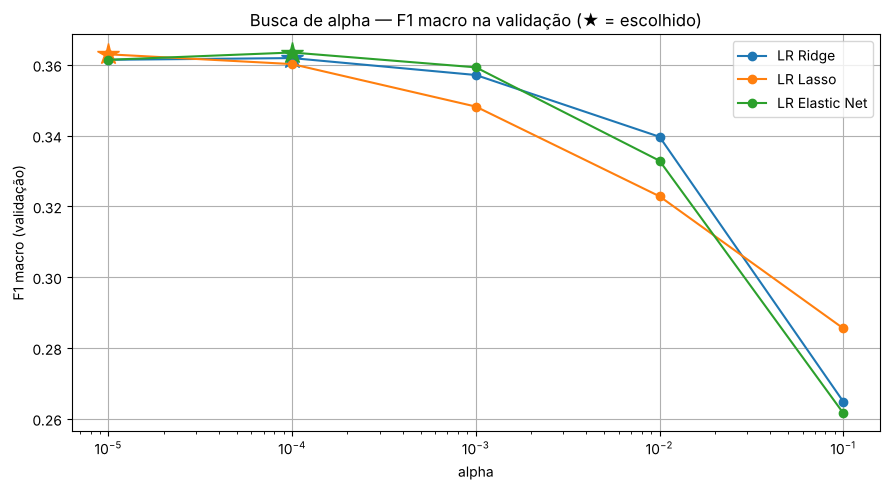

In [9]:
PENALTIES = {'LR sem regularizacao': None, 'LR Ridge': 'l2',
             'LR Lasso': 'l1', 'LR Elastic Net': 'elasticnet'}
BEST_ALPHA = {'LR sem regularizacao': 0.0}


def treinar_lr(Z, y, family, seed, alpha=None):
    penalty = PENALTIES[family]
    alpha = BEST_ALPHA[family] if alpha is None else alpha
    model = SGDClassifier(loss='log_loss', penalty=penalty,
                          alpha=0.0 if penalty is None else alpha, l1_ratio=0.5,
                          learning_rate='invscaling', eta0=0.01, power_t=0.25,
                          average=True, shuffle=False, random_state=seed,
                          early_stopping=False, n_jobs=1)
    rng = np.random.default_rng(seed)
    for epoch in range(EPOCHS):
        order = rng.permutation(len(y))
        model.partial_fit(Z[order], y[order], classes=CLASSES)
    return model


def metricas(y, prediction):
    scores = {'accuracy': accuracy_score(y, prediction)}
    for avg in ['micro', 'macro', 'weighted']:
        scores[f'precision_{avg}'] = precision_score(y, prediction, labels=CLASSES, average=avg, zero_division=0)
        scores[f'recall_{avg}'] = recall_score(y, prediction, labels=CLASSES, average=avg, zero_division=0)
        scores[f'f1_{avg}'] = f1_score(y, prediction, labels=CLASSES, average=avg, zero_division=0)
    return scores


# Busca de alpha: treino completo, avaliação na validação.
processor_full = criar_preprocessador(X_train)
Z_full = processor_full.fit_transform(X_train)
Z_val_full = processor_full.transform(X_val)
alpha_rows = []
for family, penalty in PENALTIES.items():
    if penalty is None:
        continue
    for alpha in ALPHAS:
        model = treinar_lr(Z_full, y_train, family, SEED, alpha=alpha)
        alpha_rows.append({'familia': family, 'alpha': alpha,
                           'treino_f1_macro': f1_score(y_train, model.predict(Z_full), average='macro'),
                           'validacao_f1_macro': f1_score(y_val, model.predict(Z_val_full), average='macro'),
                           'coeficientes_zero_pct': float(np.mean(model.coef_ == 0) * 100)})
alpha_search = pd.DataFrame(alpha_rows)
for family, group in alpha_search.groupby('familia'):
    best = group.sort_values(['validacao_f1_macro', 'alpha'], ascending=[False, False]).iloc[0]
    BEST_ALPHA[family] = float(best.alpha)
display(alpha_search.round(4).assign(alpha=alpha_search.alpha.map('{:g}'.format)))
print('Alpha escolhido por penalidade:', BEST_ALPHA)
alpha_search.to_csv(OUT / 'busca_alpha.csv', index=False)

fig, ax = plt.subplots()
for family, group in alpha_search.groupby('familia', sort=False):
    line, = ax.plot(group.alpha, group.validacao_f1_macro, 'o-', label=family)
    ax.plot(BEST_ALPHA[family], group.set_index('alpha').loc[BEST_ALPHA[family], 'validacao_f1_macro'],
            '*', ms=16, color=line.get_color())
ax.set(xscale='log', title='Busca de alpha — F1 macro na validação (★ = escolhido)',
       xlabel='alpha', ylabel='F1 macro (validação)')
ax.legend(); fig.tight_layout()
fig.savefig(FIG / 'busca_alpha.png', dpi=150)
plt.show()

In [10]:
records, fitted = [], {}


def registrar(model, processor, sample, family, seed, fraction, kind, depth=None):
    key = f'{kind}|{family}|seed={seed}|fraction={fraction}|depth={depth}'
    Z = processor.transform(sample[FEATURES])
    metadata = {'modelo_id': key, 'familia': family, 'semente': seed,
                'fracao_treino': fraction, 'n_treino': len(sample),
                'experimento': kind, 'max_depth': depth,
                'alpha': BEST_ALPHA.get(family)}
    train_metrics = metricas(sample[TARGET], model.predict(Z))
    val_metrics = metricas(y_val, model.predict(processor.transform(X_val)))
    row = dict(metadata, **{'treino_' + k: v for k, v in train_metrics.items()},
               **{'validacao_' + k: v for k, v in val_metrics.items()})
    if family == 'AD propria':
        row.update(altura_real=model.depth_, nos=model.node_count_)
    else:
        row['coeficientes_zero_pct'] = float(np.mean(model.coef_ == 0) * 100)
    records.append(row)
    fitted[key] = (model, processor)
    return key

start = time.perf_counter()
# Curva de complexidade da AD: treino completo, profundidades 1 até a altura limite.
for depth in range(1, MAX_DEPTH + 1):
    tree = ArvoreDecisaoPropria(max_depth=depth, min_samples_leaf=8).fit(Z_full, y_train)
    registrar(tree, processor_full, train, 'AD propria', SEED, 1.0, 'curva_ad', depth)
tree_curve = pd.DataFrame(records).sort_values('max_depth')
# Profundidade da consistência: melhor F1 macro de validação (empate -> menor profundidade).
BEST_DEPTH = int(tree_curve.sort_values(['validacao_f1_macro', 'max_depth'],
                                        ascending=[False, True]).iloc[0].max_depth)
print('Profundidade escolhida para a AD:', BEST_DEPTH)

# Curvas da LR (alpha já escolhido) e consistência da AD nos mesmos subconjuntos.
for seed in SEEDS:
    for fraction in FRACTIONS:
        sample = POOLS[seed][fraction]
        processor = criar_preprocessador(sample[FEATURES])
        Z = processor.fit_transform(sample[FEATURES])
        y = sample[TARGET].to_numpy()
        for family in PENALTIES:
            model = treinar_lr(Z, y, family, seed)
            registrar(model, processor, sample, family, seed, fraction, 'curva_lr')
        if fraction in [0.30, 0.60, 0.90]:
            tree = ArvoreDecisaoPropria(max_depth=BEST_DEPTH, min_samples_leaf=8).fit(Z, y)
            registrar(tree, processor, sample, 'AD propria', seed, fraction, 'consistencia_ad', BEST_DEPTH)
    print('Semente concluída:', seed)

results = pd.DataFrame(records)
results['gap_f1_macro'] = results.treino_f1_macro - results.validacao_f1_macro
assert len(results) == 81 and results.modelo_id.is_unique
results.to_csv(OUT / 'treino_validacao_todos_casos.csv', index=False)
print('Modelos treinados:', len(results), 'Tempo (s):', round(time.perf_counter() - start, 2))
display(results.head())

Profundidade escolhida para a AD: 5


Semente concluída: 42


Semente concluída: 43


Semente concluída: 44
Modelos treinados: 81 Tempo (s): 71.02


,modelo_id,familia,semente,fracao_treino,n_treino,experimento,max_depth,alpha,treino_accuracy,treino_precision_micro,...,validacao_precision_macro,validacao_recall_macro,validacao_f1_macro,validacao_precision_weighted,validacao_recall_weighted,validacao_f1_weighted,altura_real,nos,coeficientes_zero_pct,gap_f1_macro
0,curva_ad|AD propria|seed=42|fraction=1.0|depth=1,AD propria,42,1.0,3600,curva_ad,1.0,NaN,0.393611,0.393611,...,0.158519,0.335745,0.212998,0.184413,0.386667,0.246999,1.0,3.0,NaN,0.004993
1,curva_ad|AD propria|seed=42|fraction=1.0|depth=2,AD propria,42,1.0,3600,curva_ad,2.0,NaN,0.426667,0.426667,...,0.237585,0.371323,0.287377,0.264613,0.418333,0.321775,2.0,7.0,NaN,0.006254
2,curva_ad|AD propria|seed=42|fraction=1.0|depth=3,AD propria,42,1.0,3600,curva_ad,3.0,NaN,0.438611,0.438611,...,0.239086,0.374830,0.287115,0.265891,0.424167,0.322000,3.0,15.0,NaN,0.009809
3,curva_ad|AD propria|seed=42|fraction=1.0|depth=4,AD propria,42,1.0,3600,curva_ad,4.0,NaN,0.465000,0.465000,...,0.332696,0.400831,0.326945,0.353576,0.445000,0.361857,4.0,31.0,NaN,0.020371
4,curva_ad|AD propria|seed=42|fraction=1.0|depth=5,AD propria,42,1.0,3600,curva_ad,5.0,NaN,0.483611,0.483611,...,0.425906,0.422250,0.423092,0.444742,0.442500,0.442669,5.0,63.0,NaN,0.038358


## 7. Consistência: 30%, 60% e 90% da partição de treino

LR-GD Ridge (alpha escolhido na seção 6.1) e AD própria (profundidade escolhida pela curva de complexidade), treinadas nos mesmos subconjuntos com três sementes. Apresentamos média, desvio-padrão, mínimo–máximo, gap treino–validação e a diferença pareada AD − LR por semente.

In [11]:
consistency = results[((results.experimento == 'curva_lr') & (results.familia == 'LR Ridge')
                       & results.fracao_treino.isin([0.30, 0.60, 0.90]))
                      | (results.experimento == 'consistencia_ad')].copy()
assert len(consistency) == 18
summary = consistency.groupby(['familia', 'fracao_treino', 'n_treino']).agg(
    treino_media=('treino_f1_macro', 'mean'), validacao_media=('validacao_f1_macro', 'mean'),
    validacao_desvio=('validacao_f1_macro', 'std'),
    validacao_min=('validacao_f1_macro', 'min'), validacao_max=('validacao_f1_macro', 'max'),
    gap_medio=('gap_f1_macro', 'mean')).reset_index()
display(summary)
paired = consistency.pivot(index=['semente', 'fracao_treino'], columns='familia', values='validacao_f1_macro')
paired['diferenca_AD_menos_LR'] = paired['AD propria'] - paired['LR Ridge']
display(paired)
summary.to_csv(OUT / 'consistencia_resumo.csv', index=False)
paired.to_csv(OUT / 'consistencia_pareada.csv')

,familia,fracao_treino,n_treino,treino_media,validacao_media,validacao_desvio,validacao_min,validacao_max,gap_medio
0,AD propria,0.3,1080,0.464015,0.375381,0.027461,0.358220,0.407053,0.088634
1,AD propria,0.6,2160,0.433632,0.364796,0.023137,0.349248,0.391385,0.068836
2,AD propria,0.9,3240,0.459435,0.413579,0.007564,0.404912,0.418852,0.045856
3,LR Ridge,0.3,1080,0.446914,0.363782,0.017411,0.346321,0.381141,0.083132
4,LR Ridge,0.6,2160,0.418606,0.359323,0.005817,0.352764,0.363856,0.059283
5,LR Ridge,0.9,3240,0.404393,0.365388,0.007445,0.360954,0.373983,0.039006


familia                AD propria  LR Ridge  diferenca_AD_menos_LR
semente fracao_treino                                             
42      0.3              0.358220  0.363883              -0.005664
        0.6              0.349248  0.352764              -0.003516
        0.9              0.416972  0.373983               0.042989
43      0.3              0.360870  0.381141              -0.020272
        0.6              0.353753  0.363856              -0.010103
        0.9              0.404912  0.360954               0.043958
44      0.3              0.407053  0.346321               0.060732
        0.6              0.391385  0.361350               0.030035
        0.9              0.418852  0.361225               0.057627

## 8. Cinco gráficos de curvas

- **Curvas 1–4 (LR-GD):** F1 macro de treino e validação versus número de instâncias de treino (10%, 30%, 60%, 90% e 100% do treino), com média ± desvio de três sementes.
- **Curva 5 (AD):** F1 macro de treino e validação versus profundidade máxima permitida, de 1 até a altura limite de 12.

Treino alto com validação baixa indica sobreajuste; as duas curvas baixas e próximas indicam subajuste ou pouca informação nos atributos.

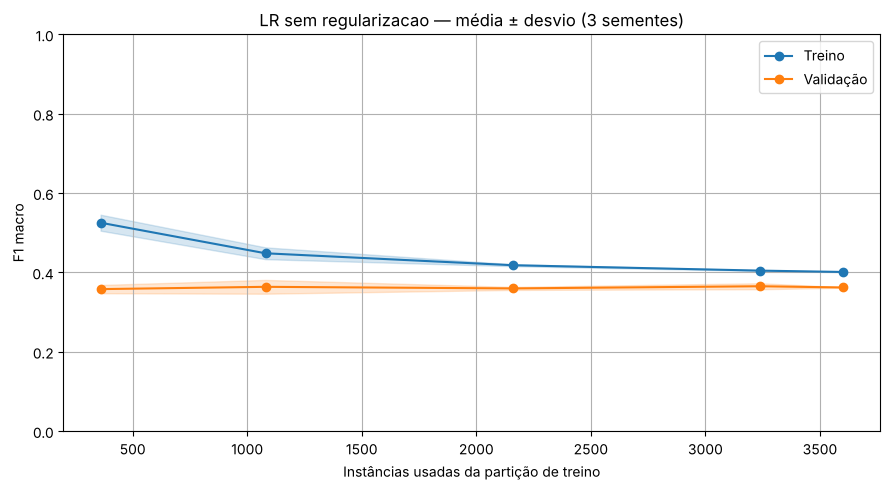

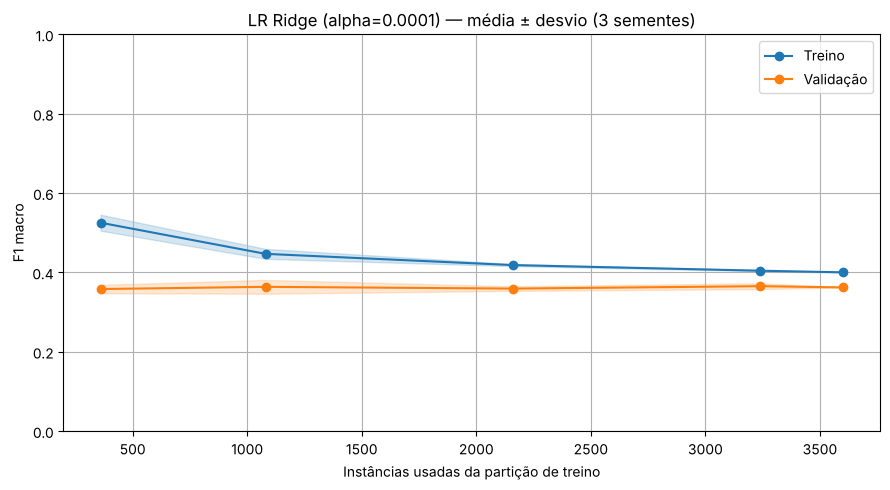

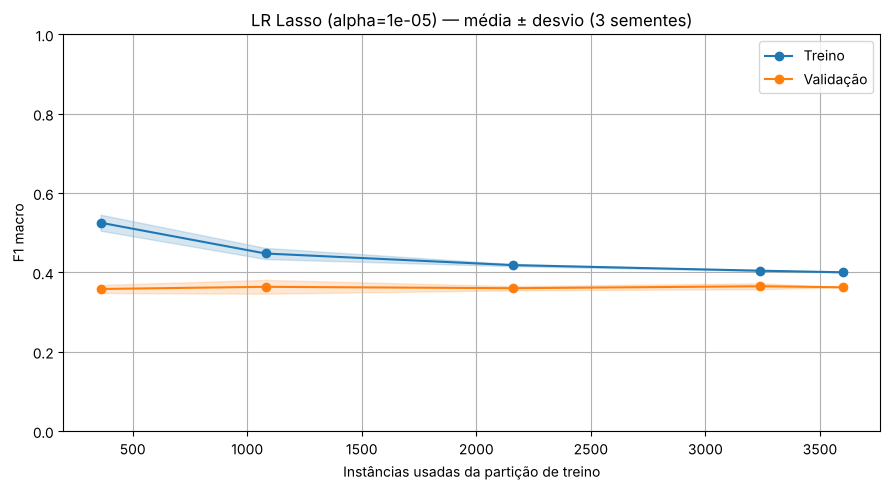

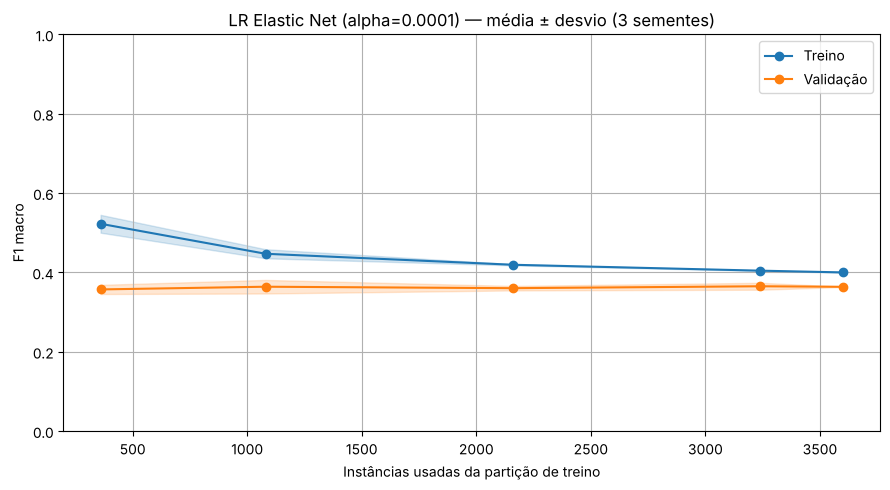

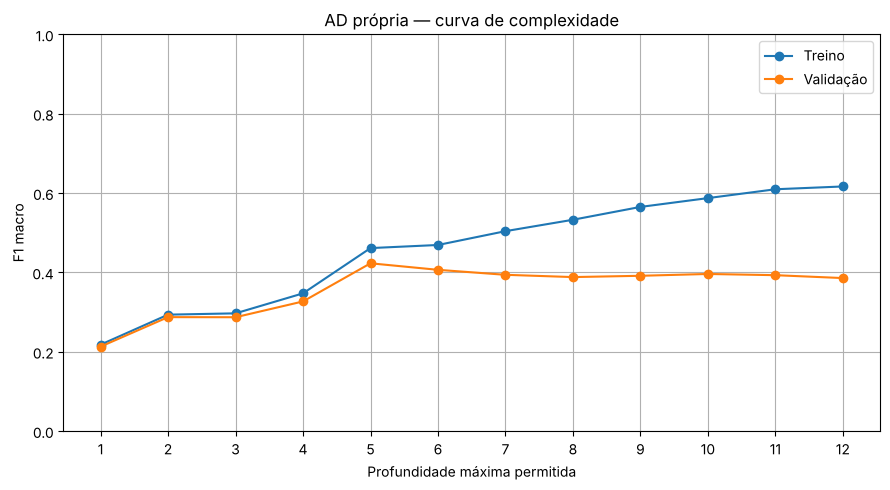

,max_depth,altura_real,nos,treino_f1_macro,validacao_f1_macro,gap_f1_macro
0,1.0,1.0,3.0,0.217992,0.212998,0.004993
1,2.0,2.0,7.0,0.293631,0.287377,0.006254
2,3.0,3.0,15.0,0.296924,0.287115,0.009809
3,4.0,4.0,31.0,0.347316,0.326945,0.020371
4,5.0,5.0,63.0,0.461450,0.423092,0.038358
5,6.0,6.0,115.0,0.469267,0.406644,0.062623
6,7.0,7.0,193.0,0.504111,0.394081,0.110030
7,8.0,8.0,281.0,0.532865,0.388355,0.144510
8,9.0,9.0,379.0,0.565238,0.391612,0.173626
9,10.0,10.0,463.0,0.587462,0.396201,0.191262


In [12]:
learning_plots = []
for index, family in enumerate(PENALTIES, start=1):
    subset = results[(results.experimento == 'curva_lr') & (results.familia == family)]
    aggregated = subset.groupby('n_treino')[['treino_f1_macro', 'validacao_f1_macro']].agg(['mean', 'std'])
    fig, ax = plt.subplots()
    x = aggregated.index.to_numpy()
    for column, label, color in [('treino_f1_macro', 'Treino', 'tab:blue'),
                                 ('validacao_f1_macro', 'Validação', 'tab:orange')]:
        mean = aggregated[column]['mean'].to_numpy()
        std = aggregated[column]['std'].to_numpy()
        ax.plot(x, mean, 'o-', label=label, color=color)
        ax.fill_between(x, mean - std, mean + std, alpha=0.18, color=color)
    alpha_txt = '' if PENALTIES[family] is None else f' (alpha={BEST_ALPHA[family]:g})'
    ax.set(title=family + alpha_txt + ' — média ± desvio (3 sementes)',
           xlabel='Instâncias usadas da partição de treino', ylabel='F1 macro', ylim=(0, 1))
    ax.legend(); fig.tight_layout()
    name = f'curva_{index}_lr.png'
    fig.savefig(FIG / name, dpi=150); learning_plots.append(name)
    plt.show()

tree_curve = results[results.experimento == 'curva_ad'].sort_values('max_depth')
fig, ax = plt.subplots()
ax.plot(tree_curve.max_depth, tree_curve.treino_f1_macro, 'o-', label='Treino')
ax.plot(tree_curve.max_depth, tree_curve.validacao_f1_macro, 'o-', label='Validação')
ax.set(title='AD própria — curva de complexidade', xlabel='Profundidade máxima permitida',
       ylabel='F1 macro', ylim=(0, 1), xticks=range(1, MAX_DEPTH + 1))
ax.legend(); fig.tight_layout()
name = 'curva_5_ad.png'
fig.savefig(FIG / name, dpi=150); learning_plots.append(name)
plt.show()
assert len(learning_plots) == 5
display(tree_curve[['max_depth', 'altura_real', 'nos', 'treino_f1_macro', 'validacao_f1_macro', 'gap_f1_macro']])

## 9. Seleção de três modelos antes do teste

Escolha feita apenas com a validação:

1. LR sem regularização, treino completo, semente 42: referência sem penalidade.
2. Melhor LR regularizada pelo F1 macro médio de validação nas três sementes, treino completo, semente 42.
3. AD com maior F1 macro de validação na curva de profundidade (empate favorece a menor profundidade).

In [13]:
lr_full = results[(results.experimento == 'curva_lr') & (results.fracao_treino == 1.0)]
rank_regularized = lr_full[lr_full.familia != 'LR sem regularizacao'].groupby('familia').validacao_f1_macro.mean().sort_values(ascending=False, kind='stable')
best_regularized = rank_regularized.index[0]
selected = [lr_full[(lr_full.familia == family) & (lr_full.semente == SEED)].iloc[0].modelo_id
            for family in ['LR sem regularizacao', best_regularized]]
selected.append(tree_curve.sort_values(['validacao_f1_macro', 'max_depth'], ascending=[False, True]).iloc[0].modelo_id)
assert len(set(selected)) == 3
selection = results[results.modelo_id.isin(selected)].copy()
selection['criterio'] = selection.familia.map({
    'LR sem regularizacao': 'referencia sem penalidade; treino 100%; seed 42',
    best_regularized: 'melhor familia regularizada pela media de validacao; treino 100%; seed 42',
    'AD propria': 'melhor profundidade na validacao; empate favorece menor altura'})
selection.to_csv(OUT / 'selecao_antes_teste.csv', index=False)
display(selection[['modelo_id', 'validacao_f1_macro', 'criterio']])
SELECTION_FROZEN = True

,modelo_id,validacao_f1_macro,criterio
4,curva_ad|AD propria|seed=42|fraction=1.0|depth=5,0.423092,melhor profundidade na validacao; empate favor...
31,curva_lr|LR sem regularizacao|seed=42|fraction...,0.361521,referencia sem penalidade; treino 100%; seed 42
34,curva_lr|LR Elastic Net|seed=42|fraction=1.0|d...,0.363487,melhor familia regularizada pela media de vali...


## 10. Avaliação final no teste de todos os casos

Só agora o teste é transformado e predito: todos os pontos das quatro curvas da LR, todas as profundidades da AD e os casos de consistência.

Precision = TP/(TP+FP); recall = TP/(TP+FN); F1 = 2PR/(P+R). Macro é a média simples entre classes; micro agrega as contagens de todas as classes (em classificação multiclasse de rótulo único, F1 micro = acurácia). Baseline: prever sempre a classe mais frequente do treino.

In [14]:
assert SELECTION_FROZEN
X_test, y_test = test[FEATURES], test[TARGET].to_numpy()
test_rows, per_class, predictions = [], [], {}
for _, row in results.iterrows():
    key = row.modelo_id
    model, processor = fitted[key]
    pred = model.predict(processor.transform(X_test))
    predictions[key] = pred
    test_rows.append({'modelo_id': key, **metricas(y_test, pred)})
    report = classification_report(y_test, pred, labels=CLASSES, output_dict=True, zero_division=0)
    for label in CLASSES:
        per_class.append({'modelo_id': key, 'classe': label, **report[str(label)]})
test_metrics = results.merge(pd.DataFrame(test_rows), on='modelo_id', validate='one_to_one')
assert len(test_metrics) == len(results)
assert np.allclose(test_metrics.f1_micro, test_metrics.accuracy)
test_metrics.to_csv(OUT / 'metricas_teste_todos_casos.csv', index=False)
pd.DataFrame(per_class).to_csv(OUT / 'metricas_teste_por_classe.csv', index=False)
columns = ['familia', 'experimento', 'fracao_treino', 'max_depth', 'precision_macro', 'recall_macro', 'f1_micro', 'f1_macro']
# Mostrar TODAS as configurações de curvas; repetições resumidas por média.
display(test_metrics[test_metrics.experimento == 'curva_lr'].groupby(['familia', 'fracao_treino'])[
    ['precision_macro', 'recall_macro', 'f1_micro', 'f1_macro']].agg(['mean', 'std']))
display(test_metrics[test_metrics.experimento == 'curva_ad'][columns])
baseline = DummyClassifier(strategy='most_frequent').fit(np.zeros((len(train), 1)), y_train)
baseline_scores = metricas(y_test, baseline.predict(np.zeros((len(test), 1))))
pd.DataFrame([baseline_scores]).to_csv(OUT / 'baseline_teste.csv', index=False)
print('Baseline majoritário:'); display(pd.DataFrame([baseline_scores]))
display(test_metrics[test_metrics.modelo_id.isin(selected)][columns])

precision_macro           recall_macro  \
                                              mean       std         mean   
familia              fracao_treino                                          
LR Elastic Net       0.1                  0.363617  0.018016     0.396681   
                     0.3                  0.363329  0.020969     0.403959   
                     0.6                  0.359447  0.006074     0.404547   
                     0.9                  0.349662  0.011764     0.400418   
                     1.0                  0.328929  0.001718     0.394254   
LR Lasso             0.1                  0.364368  0.018759     0.397097   
                     0.3                  0.362896  0.020915     0.403459   
                     0.6                  0.360132  0.007488     0.404913   
                     0.9                  0.352374  0.010936     0.401108   
                     1.0                  0.332080  0.001819     0.395037   
LR Ridge             0.1                  0.363565  0.018653     0.396490   
                     0.3                  0.363241  0.021398     0.403711   
                     0.6                  0.359528  0.006554     0.404839   
                     0.9                  0.352107  0.011738     0.400789   
                     1.0                  0.333354  0.000680     0.395363   
LR sem regularizacao 0.1                  0.363241  0.019171     0.396239   
                     0.3                  0.363663  0.021244     0.403996   
                     0.6                  0.358941  0.006714     0.404357   
                     0.9                  0.351410  0.011914     0.400559   
                     1.0                  0.333354  0.000680     0.395363   

                                              f1_micro            f1_macro  \
                                         std      mean       std      mean   
familia              fracao_treino                                           
LR Elastic Net       0.1            0.006719  0.436667  0.004330  0.360607   
                     0.3            0.009416  0.447778  0.007876  0.358273   
                     0.6            0.005116  0.449444  0.005358  0.354687   
                     0.9            0.004410  0.446389  0.003849  0.346956   
                     1.0            0.001296  0.441389  0.001273  0.336960   
LR Lasso             0.1            0.006739  0.436944  0.004111  0.361404   
                     0.3            0.009728  0.447222  0.008221  0.357954   
                     0.6            0.006316  0.449722  0.006473  0.355517   
                     0.9            0.004706  0.446944  0.004111  0.348472   
                     1.0            0.000532  0.441944  0.000481  0.338626   
LR Ridge             0.1            0.006594  0.436389  0.003938  0.360659   
                     0.3            0.010162  0.447500  0.008700  0.358131   
                     0.6            0.005763  0.449722  0.005912  0.355155   
                     0.9            0.004917  0.446667  0.004330  0.348032   
                     1.0            0.000493  0.442222  0.000481  0.339173   
LR sem regularizacao 0.1            0.006943  0.436111  0.004276  0.360538   
                     0.3            0.009954  0.447778  0.008512  0.358482   
                     0.6            0.005884  0.449167  0.006009  0.354874   
                     0.9            0.005097  0.446389  0.004590  0.348007   
                     1.0            0.000493  0.442222  0.000481  0.339173   

                                              
                                         std  
familia              fracao_treino            
LR Elastic Net       0.1            0.014587  
                     0.3            0.012870  
                     0.6            0.005626  
                     0.9            0.006570  
                     1.0            0.001409  
LR Lasso             0.1            0.014835  
                     0.3            0.013124 

,familia,experimento,fracao_treino,max_depth,precision_macro,recall_macro,f1_micro,f1_macro
0,AD propria,curva_ad,1.0,1.0,0.163426,0.342378,0.394167,0.218485
1,AD propria,curva_ad,1.0,2.0,0.240032,0.375792,0.423333,0.291022
2,AD propria,curva_ad,1.0,3.0,0.241081,0.380393,0.430833,0.290379
3,AD propria,curva_ad,1.0,4.0,0.318658,0.415413,0.461667,0.339966
4,AD propria,curva_ad,1.0,5.0,0.419817,0.418026,0.440000,0.415909
5,AD propria,curva_ad,1.0,6.0,0.412811,0.415593,0.442500,0.407498
6,AD propria,curva_ad,1.0,7.0,0.407669,0.414317,0.440000,0.407453
7,AD propria,curva_ad,1.0,8.0,0.395833,0.404612,0.430000,0.398941
8,AD propria,curva_ad,1.0,9.0,0.379246,0.388614,0.413333,0.382574
9,AD propria,curva_ad,1.0,10.0,0.389743,0.399086,0.422500,0.393102


Baseline majoritário:


,accuracy,precision_micro,recall_micro,f1_micro,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,0.240833,0.240833,0.240833,0.240833,0.048167,0.2,0.077636,0.058001,0.240833,0.093487


,familia,experimento,fracao_treino,max_depth,precision_macro,recall_macro,f1_micro,f1_macro
4,AD propria,curva_ad,1.0,5.0,0.419817,0.418026,0.440000,0.415909
31,LR sem regularizacao,curva_lr,1.0,NaN,0.333747,0.395648,0.442500,0.339472
34,LR Elastic Net,curva_lr,1.0,NaN,0.328874,0.394472,0.441667,0.337048


## 11. Três matrizes de confusão e análise de erros

Contagens absolutas dos três modelos selecionados, com a mesma ordem de classes (da menor para a maior nota). Exportamos também as matrizes normalizadas por linha (recall por classe) e as três confusões mais frequentes de cada modelo.

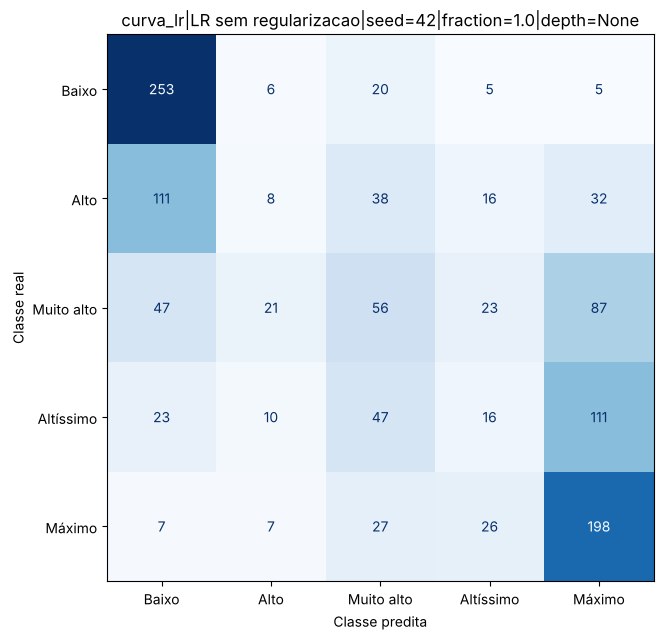

Principais confusões (quantidade, real, predita): [(111, 'Altíssimo', 'Máximo'), (111, 'Alto', 'Baixo'), (87, 'Muito alto', 'Máximo')]


,classe,recall,suporte
0,Baixo,0.875433,289
1,Alto,0.039024,205
2,Muito alto,0.239316,234
3,Altíssimo,0.077295,207
4,Máximo,0.747170,265


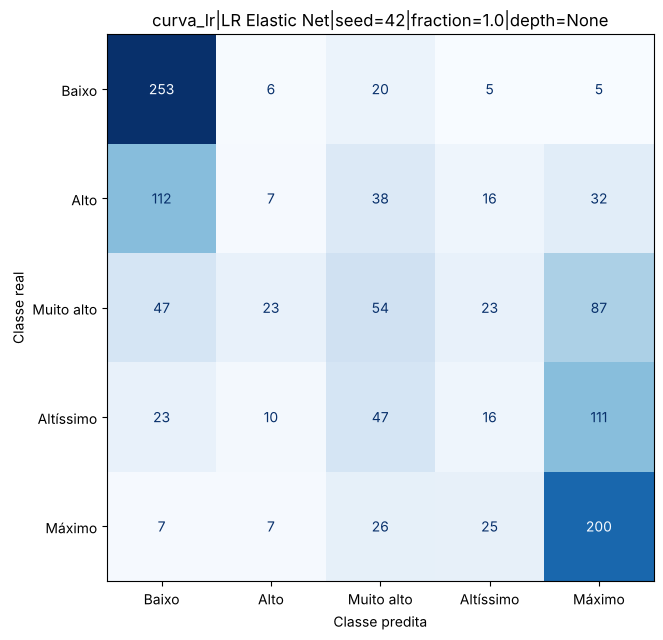

Principais confusões (quantidade, real, predita): [(112, 'Alto', 'Baixo'), (111, 'Altíssimo', 'Máximo'), (87, 'Muito alto', 'Máximo')]


,classe,recall,suporte
0,Baixo,0.875433,289
1,Alto,0.034146,205
2,Muito alto,0.230769,234
3,Altíssimo,0.077295,207
4,Máximo,0.754717,265


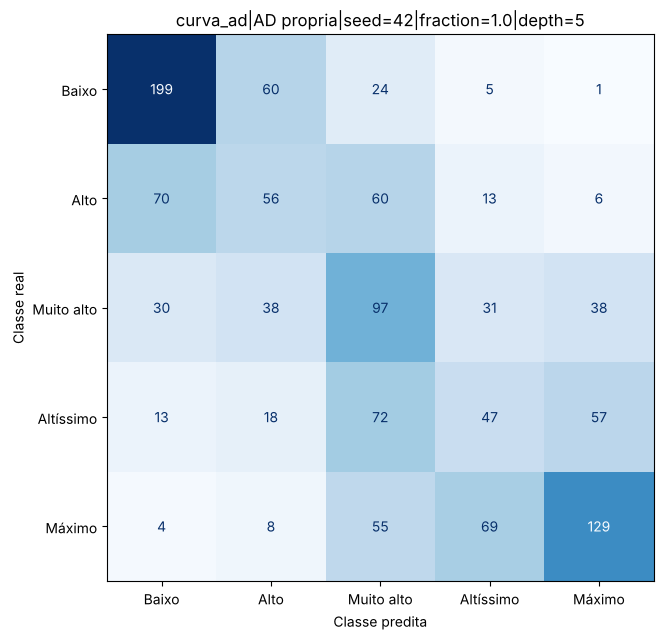

Principais confusões (quantidade, real, predita): [(72, 'Altíssimo', 'Muito alto'), (70, 'Alto', 'Baixo'), (69, 'Máximo', 'Altíssimo')]


,classe,recall,suporte
0,Baixo,0.688581,289
1,Alto,0.273171,205
2,Muito alto,0.414530,234
3,Altíssimo,0.227053,207
4,Máximo,0.486792,265


In [15]:
error_summaries = []
for index, key in enumerate(selected, start=1):
    matrix = confusion_matrix(y_test, predictions[key], labels=CLASSES)
    assert matrix.shape == (len(CLASSES), len(CLASSES)) and matrix.sum() == len(test)
    normalized = np.divide(matrix, matrix.sum(axis=1, keepdims=True),
                           out=np.zeros_like(matrix, dtype=float), where=matrix.sum(axis=1, keepdims=True) != 0)
    pd.DataFrame(matrix, index=CLASSES, columns=CLASSES).to_csv(OUT / f'confusao_{index}_contagens.csv')
    pd.DataFrame(normalized, index=CLASSES, columns=CLASSES).to_csv(OUT / f'confusao_{index}_normalizada.csv')
    fig, ax = plt.subplots(figsize=(8, 6.5))
    ConfusionMatrixDisplay(matrix, display_labels=CLASSES).plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=0)
    ax.set_title(key); ax.set_xlabel('Classe predita'); ax.set_ylabel('Classe real')
    ax.grid(False); fig.tight_layout()
    fig.savefig(FIG / f'matriz_confusao_{index}.png', dpi=150)
    plt.show()
    error_pairs = sorted([(int(matrix[i, j]), str(CLASSES[i]), str(CLASSES[j]))
                          for i in range(len(CLASSES)) for j in range(len(CLASSES)) if i != j and matrix[i, j] > 0], reverse=True)
    top = error_pairs[:3]
    recalls = dict(zip(CLASSES.tolist(), np.diag(normalized).tolist()))
    error_summaries.append({'modelo_id': key, 'principais_erros': top, 'recall_por_classe': recalls})
    print('Principais confusões (quantidade, real, predita):', top)
    display(pd.DataFrame({'classe': CLASSES, 'recall': np.diag(normalized), 'suporte': matrix.sum(axis=1)}))
# Exportar predições dos três selecionados para auditoria individual.
prediction_table = test[[NOTA, TARGET]].rename_axis('linha').reset_index()
for index, key in enumerate(selected, start=1):
    prediction_table[f'predicao_modelo_{index}'] = predictions[key]
prediction_table.to_csv(OUT / 'predicoes_selecionados.csv', index=False)

## 12. Relatório de resultados

A célula abaixo gera `resultados/relatorio_resultados.md` com os números desta execução.

In [16]:
selected_metrics = test_metrics.set_index('modelo_id').loc[selected]
lines = ['# Resultados da execução — GTA VI', '',
         '## Configuração',
         f'{len(df)} registros; alvo {TARGET} com 5 classes ({", ".join(f"{k}: notas {min(v)}–{max(v)}" if len(v) > 1 else f"{k}: nota {v[0]}" for k, v in FAIXAS.items())}). '
         f'Removidos de X: respondent_id (identificador), overall_sentiment (derivado da nota) e {NOTA}.', '',
         f'Treino={len(train)}; validação={len(val)}; teste={len(test)}. Sementes={SEEDS}; épocas SGD={EPOCHS}; '
         f'alpha escolhido: {BEST_ALPHA}; profundidade AD escolhida={BEST_DEPTH} (limite {MAX_DEPTH}). '
         f'{len(results)} configurações avaliadas no teste.', '',
         '## Busca de alpha (validação, F1 macro)', alpha_search.round(4).assign(alpha=alpha_search.alpha.map('{:g}'.format)).to_markdown(index=False), '',
         '## Métricas dos três modelos selecionados (teste)',
         '|Modelo|Precision macro|Recall macro|F1 micro|F1 macro|Gap treino-validação|',
         '|---|---:|---:|---:|---:|---:|']
for key, row in selected_metrics.iterrows():
    safe_key = key.replace('|', '&#124;')
    lines.append(f'|{safe_key}|{row.precision_macro:.4f}|{row.recall_macro:.4f}|{row.f1_micro:.4f}|{row.f1_macro:.4f}|{row.gap_f1_macro:.4f}|')
lines += ['', f'Baseline majoritário: F1 micro={baseline_scores["f1_micro"]:.4f}; '
          f'F1 macro={baseline_scores["f1_macro"]:.4f}.', '', '## Curvas']
for family in PENALTIES:
    curve = results[(results.experimento == 'curva_lr') & (results.familia == family)]
    first = curve[curve.fracao_treino == min(FRACTIONS)]
    last = curve[curve.fracao_treino == 1]
    lines.append(f'- {family}: validação F1 macro {first.validacao_f1_macro.mean():.4f} ({first.n_treino.iloc[0]} exemplos) → '
                 f'{last.validacao_f1_macro.mean():.4f} ({last.n_treino.iloc[0]}); gap final {last.gap_f1_macro.mean():.4f}.')
lines += [f'- AD: treino {tree_curve.iloc[0].treino_f1_macro:.4f} → {tree_curve.iloc[-1].treino_f1_macro:.4f}; '
          f'validação {tree_curve.iloc[0].validacao_f1_macro:.4f} → {tree_curve.iloc[-1].validacao_f1_macro:.4f} '
          f'(profundidade 1 → {MAX_DEPTH}); melhor validação na profundidade {BEST_DEPTH}.', '',
          '## Consistência', summary.round(4).to_markdown(index=False), '',
          '## Erros dos selecionados']
for item in error_summaries:
    lines += [f'### {item["modelo_id"]}',
              'Confusões principais: ' + '; '.join(f'{real} → {pred}: {count}' for count, real, pred in item['principais_erros']),
              'Recall por classe: ' + '; '.join(f'{k}={v:.4f}' for k, v in item['recall_por_classe'].items()), '']
lines += ['## Reprodutibilidade', json.dumps(VERSIONS, indent=2)]
report_text = '\n'.join(lines)
(OUT / 'relatorio_resultados.md').write_text(report_text, encoding='utf-8')
manifest = {'dataset': str(DATASET.relative_to(ROOT)),
            'dataset_sha256': hashlib.sha256(DATASET.read_bytes()).hexdigest(),
            'shape_sem_id': list(df.shape), 'target': TARGET, 'faixas': {k: list(v) for k, v in FAIXAS.items()},
            'removidos_de_X': REMOVIDOS + ['respondent_id'],
            'split_sizes': {'train': len(train), 'validation': len(val), 'test': len(test)},
            'seeds': SEEDS, 'fractions': FRACTIONS, 'epochs': EPOCHS, 'alphas_testados': ALPHAS,
            'alpha_escolhido': BEST_ALPHA, 'profundidade_escolhida': BEST_DEPTH,
            'tree_depth_limit': MAX_DEPTH, 'configurations': len(results),
            'learning_plots': learning_plots, 'selected_model_ids': selected,
            'selection_uses_test': False, 'features': FEATURES, 'versions': VERSIONS}
(OUT / 'manifesto.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
display(Markdown(report_text))
print('Artefatos gravados em:', OUT)

# Resultados da execução — GTA VI

## Configuração
6000 registros; alvo classe_hype com 5 classes (Baixo: notas 1–6, Alto: nota 7, Muito alto: nota 8, Altíssimo: nota 9, Máximo: nota 10). Removidos de X: respondent_id (identificador), overall_sentiment (derivado da nota) e hype_score_1to10.

Treino=3600; validação=1200; teste=1200. Sementes=[42, 43, 44]; épocas SGD=160; alpha escolhido: {'LR sem regularizacao': 0.0, 'LR Elastic Net': 0.0001, 'LR Lasso': 1e-05, 'LR Ridge': 0.0001}; profundidade AD escolhida=5 (limite 12). 81 configurações avaliadas no teste.

## Busca de alpha (validação, F1 macro)
| familia        |   alpha |   treino_f1_macro |   validacao_f1_macro |   coeficientes_zero_pct |
|:---------------|--------:|------------------:|---------------------:|------------------------:|
| LR Ridge       |  1e-05  |            0.4019 |               0.3614 |                       0 |
| LR Ridge       |  0.0001 |            0.4001 |               0.3619 |                       0 |
| LR Ridge       |  0.001  |            0.3974 |               0.3571 |                       0 |
| LR Ridge       |  0.01   |            0.3723 |               0.3397 |                       0 |
| LR Ridge       |  0.1    |            0.2751 |               0.2649 |                       0 |
| LR Lasso       |  1e-05  |            0.4001 |               0.363  |                       0 |
| LR Lasso       |  0.0001 |            0.3996 |               0.3602 |                       0 |
| LR Lasso       |  0.001  |            0.3814 |               0.3482 |                       0 |
| LR Lasso       |  0.01   |            0.327  |               0.3229 |                       0 |
| LR Lasso       |  0.1    |            0.272  |               0.2856 |                       0 |
| LR Elastic Net |  1e-05  |            0.4006 |               0.3614 |                       0 |
| LR Elastic Net |  0.0001 |            0.4003 |               0.3635 |                       0 |
| LR Elastic Net |  0.001  |            0.391  |               0.3593 |                       0 |
| LR Elastic Net |  0.01   |            0.3439 |               0.3329 |                       0 |
| LR Elastic Net |  0.1    |            0.2522 |               0.2616 |                       0 |

## Métricas dos três modelos selecionados (teste)
|Modelo|Precision macro|Recall macro|F1 micro|F1 macro|Gap treino-validação|
|---|---:|---:|---:|---:|---:|
|curva_lr&#124;LR sem regularizacao&#124;seed=42&#124;fraction=1.0&#124;depth=None|0.3337|0.3956|0.4425|0.3395|0.0404|
|curva_lr&#124;LR Elastic Net&#124;seed=42&#124;fraction=1.0&#124;depth=None|0.3289|0.3945|0.4417|0.3370|0.0368|
|curva_ad&#124;AD propria&#124;seed=42&#124;fraction=1.0&#124;depth=5|0.4198|0.4180|0.4400|0.4159|0.0384|

Baseline majoritário: F1 micro=0.2408; F1 macro=0.0776.

## Curvas
- LR sem regularizacao: validação F1 macro 0.3580 (360 exemplos) → 0.3622 (3600); gap final 0.0391.
- LR Ridge: validação F1 macro 0.3581 (360 exemplos) → 0.3623 (3600); gap final 0.0380.
- LR Lasso: validação F1 macro 0.3583 (360 exemplos) → 0.3627 (3600); gap final 0.0378.
- LR Elastic Net: validação F1 macro 0.3572 (360 exemplos) → 0.3638 (3600); gap final 0.0363.
- AD: treino 0.2180 → 0.6168; validação 0.2130 → 0.3859 (profundidade 1 → 12); melhor validação na profundidade 5.

## Consistência
| familia    |   fracao_treino |   n_treino |   treino_media |   validacao_media |   validacao_desvio |   validacao_min |   validacao_max |   gap_medio |
|:-----------|----------------:|-----------:|---------------:|------------------:|-------------------:|----------------:|----------------:|------------:|
| AD propria |             0.3 |       1080 |         0.464  |            0.3754 |             0.0275 |          0.3582 |          0.4071 |      0.0886 |
| AD propria |             0.6 |       2160 |         0.4336 |            0.3648 |             0.0231 |          0.3492 |          0.3914 |      0.0688 |
| AD propria |             0.9 |       3240 |         0.4594 |            0.4136 |             0.0076 |          0.4049 |          0.4189 |      0.0459 |
| LR Ridge   |             0.3 |       1080 |         0.4469 |            0.3638 |             0.0174 |          0.3463 |          0.3811 |      0.0831 |
| LR Ridge   |             0.6 |       2160 |         0.4186 |            0.3593 |             0.0058 |          0.3528 |          0.3639 |      0.0593 |
| LR Ridge   |             0.9 |       3240 |         0.4044 |            0.3654 |             0.0074 |          0.361  |          0.374  |      0.039  |

## Erros dos selecionados
### curva_lr|LR sem regularizacao|seed=42|fraction=1.0|depth=None
Confusões principais: Altíssimo → Máximo: 111; Alto → Baixo: 111; Muito alto → Máximo: 87
Recall por classe: Baixo=0.8754; Alto=0.0390; Muito alto=0.2393; Altíssimo=0.0773; Máximo=0.7472

### curva_lr|LR Elastic Net|seed=42|fraction=1.0|depth=None
Confusões principais: Alto → Baixo: 112; Altíssimo → Máximo: 111; Muito alto → Máximo: 87
Recall por classe: Baixo=0.8754; Alto=0.0341; Muito alto=0.2308; Altíssimo=0.0773; Máximo=0.7547

### curva_ad|AD propria|seed=42|fraction=1.0|depth=5
Confusões principais: Altíssimo → Muito alto: 72; Alto → Baixo: 70; Máximo → Altíssimo: 69
Recall por classe: Baixo=0.6886; Alto=0.2732; Muito alto=0.4145; Altíssimo=0.2271; Máximo=0.4868

## Reprodutibilidade
{
  "python": "3.13.16",
  "numpy": "2.5.3",
  "pandas": "3.0.5",
  "scikit_learn": "1.9.1",
  "scipy": "1.18.1"
}

Artefatos gravados em: /home/claude/w/docs/gta6_classificacao/resultados


## 13. Resumo das métricas no teste

Precision, recall, F1 micro e F1 macro de todos os casos dos gráficos, da consistência, dos três modelos selecionados e do baseline.

In [17]:
cols = ['precision_macro', 'recall_macro', 'precision_micro', 'recall_micro', 'f1_micro', 'f1_macro']
print('Curvas LR (média das 3 sementes por tamanho de treino):')
display(test_metrics[test_metrics.experimento == 'curva_lr'].groupby(['familia', 'n_treino'])[cols].mean().round(4))
print('Curva AD (profundidade):')
display(test_metrics[test_metrics.experimento == 'curva_ad'].set_index('max_depth')[cols].round(4))
print('Consistência (30/60/90% do treino, média das 3 sementes):')
display(test_metrics[((test_metrics.experimento == 'curva_lr') & (test_metrics.familia == 'LR Ridge')
                      & test_metrics.fracao_treino.isin([0.3, 0.6, 0.9])) | (test_metrics.experimento == 'consistencia_ad')]
        .groupby(['familia', 'fracao_treino'])[cols].mean().round(4))
print('Três modelos selecionados:')
display(test_metrics.set_index('modelo_id').loc[selected, cols].round(4))
print('Baseline:')
display(pd.DataFrame([baseline_scores])[cols].round(4))

Curvas LR (média das 3 sementes por tamanho de treino):


precision_macro  recall_macro  precision_micro  \
familia              n_treino                                                   
LR Elastic Net       360                0.3636        0.3967           0.4367   
                     1080               0.3633        0.4040           0.4478   
                     2160               0.3594        0.4045           0.4494   
                     3240               0.3497        0.4004           0.4464   
                     3600               0.3289        0.3943           0.4414   
LR Lasso             360                0.3644        0.3971           0.4369   
                     1080               0.3629        0.4035           0.4472   
                     2160               0.3601        0.4049           0.4497   
                     3240               0.3524        0.4011           0.4469   
                     3600               0.3321        0.3950           0.4419   
LR Ridge             360                0.3636        0.3965           0.4364   
                     1080               0.3632        0.4037           0.4475   
                     2160               0.3595        0.4048           0.4497   
                     3240               0.3521        0.4008           0.4467   
                     3600               0.3334        0.3954           0.4422   
LR sem regularizacao 360                0.3632        0.3962           0.4361   
                     1080               0.3637        0.4040           0.4478   
                     2160               0.3589        0.4044           0.4492   
                     3240               0.3514        0.4006           0.4464   
                     3600               0.3334        0.3954           0.4422   

                               recall_micro  f1_micro  f1_macro  
familia              n_treino                                    
LR Elastic Net       360             0.4367    0.4367    0.3606  
                     1080            0.4478    0.4478    0.3583  
                     2160            0.4494    0.4494    0.3547  
                     3240            0.4464    0.4464    0.3470  
                     3600            0.4414    0.4414    0.3370  
LR Lasso             360             0.4369    0.4369    0.3614  
                     1080            0.4472    0.4472    0.3580  
                     2160            0.4497    0.4497    0.3555  
                     3240            0.4469    0.4469    0.3485  
                     3600            0.4419    0.4419    0.3386  
LR Ridge             360             0.4364    0.4364    0.3607  
                     1080            0.4475    0.4475    0.3581  
                     2160            0.4497    0.4497    0.3552  
                     3240            0.4467    0.4467    0.3480  
                     3600            0.4422    0.4422    0.3392  
LR sem regularizacao 360             0.4361    0.4361    0.3605  
                     1080            0.4478    0.4478    0.3585  
                     2160            0.4492    0.4492    0.3549  
                     3240            0.4464    0.4464    0.3480  
                     3600            0.4422    0.4422    0.3392

Curva AD (profundidade):


,precision_macro,recall_macro,precision_micro,recall_micro,f1_micro,f1_macro
max_depth,,,,,,
1.0,0.1634,0.3424,0.3942,0.3942,0.3942,0.2185
2.0,0.2400,0.3758,0.4233,0.4233,0.4233,0.2910
3.0,0.2411,0.3804,0.4308,0.4308,0.4308,0.2904
4.0,0.3187,0.4154,0.4617,0.4617,0.4617,0.3400
5.0,0.4198,0.4180,0.4400,0.4400,0.4400,0.4159
6.0,0.4128,0.4156,0.4425,0.4425,0.4425,0.4075
7.0,0.4077,0.4143,0.4400,0.4400,0.4400,0.4075
8.0,0.3958,0.4046,0.4300,0.4300,0.4300,0.3989
9.0,0.3792,0.3886,0.4133,0.4133,0.4133,0.3826


Consistência (30/60/90% do treino, média das 3 sementes):


precision_macro  recall_macro  precision_micro  \
familia    fracao_treino                                                   
AD propria 0.3                     0.3777        0.3917           0.4242   
           0.6                     0.3705        0.4136           0.4486   
           0.9                     0.4046        0.4083           0.4336   
LR Ridge   0.3                     0.3632        0.4037           0.4475   
           0.6                     0.3595        0.4048           0.4497   
           0.9                     0.3521        0.4008           0.4467   

                          recall_micro  f1_micro  f1_macro  
familia    fracao_treino                                    
AD propria 0.3                  0.4242    0.4242    0.3691  
           0.6                  0.4486    0.4486    0.3790  
           0.9                  0.4336    0.4336    0.4022  
LR Ridge   0.3                  0.4475    0.4475    0.3581  
           0.6                  0.4497    0.4497    0.3552  
           0.9                  0.4467    0.4467    0.3480

Três modelos selecionados:


,precision_macro,recall_macro,precision_micro,recall_micro,f1_micro,f1_macro
modelo_id,,,,,,
curva_lr|LR sem regularizacao|seed=42|fraction=1.0|depth=None,0.3337,0.3956,0.4425,0.4425,0.4425,0.3395
curva_lr|LR Elastic Net|seed=42|fraction=1.0|depth=None,0.3289,0.3945,0.4417,0.4417,0.4417,0.3370
curva_ad|AD propria|seed=42|fraction=1.0|depth=5,0.4198,0.4180,0.4400,0.4400,0.4400,0.4159


Baseline:


,precision_macro,recall_macro,precision_micro,recall_micro,f1_micro,f1_macro
0,0.0482,0.2,0.2408,0.2408,0.2408,0.0776


## Checklist do enunciado

|Requisito|Situação|
|---|---|
|≥ 2.000 instâncias|6.000|
|≥ 5 classes|5 classes (notas reagrupadas)|
|Texto + valores estruturados|`most_anticipated_feature` (texto, 10 frases possíveis) + atributos estruturados|
|TF-IDF|Aplicado a `most_anticipated_feature`|
|60/20/20|3.600 / 1.200 / 1.200, estratificado|
|Estudo introdutório|Seção 2, incluindo verificação de vazamento|
|LR-GD|`SGDClassifier(loss="log_loss")`, 4 penalidades, alpha escolhido na validação|
|AD com treino e predição próprios|`ArvoreDecisaoPropria` (CART/Gini), seção 5|
|Consistência 30/60/90%|LR Ridge e AD, 3 sementes|
|5 curvas|4 da LR por tamanho de treino + 1 da AD por profundidade até 12|
|Precision, recall, F1 micro/macro no teste|Todos os 81 casos + por classe|
|3 matrizes de confusão|Modelos escolhidos pela validação, seção 11|